## Historical GOTTHARD backgrounds and calibration

Compilation only; no numerical reproduction is claimed. Historical source: `/home/mmanresa/glycine26`, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Cell numbers below are zero-based and include Markdown cells. Run sections in order from a fresh kernel only in the separately approved reproduction stage. Historical inputs are read-only. Review memory before executing: historical loaders materialize full files/runs. Do not run full raw-data processing on login/display nodes.

## Setup

Local pinned helpers replace historical imports and path discovery. No historical config import or source-HDF5 write-back is included. Dependencies: NumPy, SciPy, h5py, Matplotlib and a Jupyter Python kernel. Notebook magic is omitted; plotting calls and source styles are retained. Caches are redirected inside this project.

In [3]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard')
if not (PROJECT_ROOT / 'AGENTS.md').is_file():
    raise RuntimeError(f'Project root unavailable: {PROJECT_ROOT}')
sys.dont_write_bytecode = True
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache' / 'matplotlib')
os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from historical import config
from historical import config as path_config
from historical.data_loading import ExperimentData, load_raw_h5, load_data, _align_by_tID
from historical.binning import arb_bool_ar, bin_and_average, bin_and_sum_ratio

print('Historical data:', config.DATA_ROOT)
print('Project:', PROJECT_ROOT)


Historical data: /asap3/flash/gpfs/fl24/2026/data/11022188
Project: /home/mmanresa/FLASH_Gotthard


## Dark-run comparison: original settings

Source: `analysis/notebooks/vls_compare_runs.ipynb`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; cells 3, 5, 7.

Runs 58815/58816 use dark 58814, 110 frames, roll −2, ROI [560,615), global off-bunch mean [100,108), retained bunches [0,101). The historical prose says per-train but auto_subtract_background averages across all trains and the selected bunch window. Preserve the implemented global subtraction.

Adaptations: Only setup/import paths differ. MAX_FILES=20 and scientific parameters unchanged; these runs have fewer than 20 files, so the original complete comparison runs are loaded.

In [4]:
# Raw runs to compare. Add or remove run numbers freely - every
# downstream cell loops over `runs` so adding a third run just
# adds a panel / extra line.
RUN_NOS    = [58815, 58816]
BG_RUN_NO  = 58814
MAX_FILES  = 20
TRAIN_LENGTH = 110

# Bunch-axis roll (np.roll) applied to align the Gotthard line index
# with the FEL bunch index.
GOTTHARD_ROLL = -2

# VLS pixel ROI (after roll). None keeps the full pixel axis.
ROI = (560, 615)

# Half-open bunch range used for the per-train auto background.
BG_BUNCH_RANGE = (100, 108)

# Half-open bunch range kept after baseline subtraction.
SIGNAL_BUNCH_RANGE = (0, 101)

# Log-stretch the bunch / train maps.
LOG_MAP = False

print(f"runs to compare : {RUN_NOS}")
print(f"background run  : {BG_RUN_NO}")
print(f"max files / run : {MAX_FILES}")
print(f"ROI             : {ROI}")
print(f"gotthard roll   : {GOTTHARD_ROLL}")

runs to compare : [58815, 58816]
background run  : 58814
max files / run : 20
ROI             : (560, 615)
gotthard roll   : -2


Loading 1 raw H5 file(s) for run 58814 (config 2).
  reading FLASH2_USER1_main_run58814_file1_20260605T232039.1.h5
Loaded 342 trains x 110 bunches.
background source: run 58814
background shape : (110, 1280)


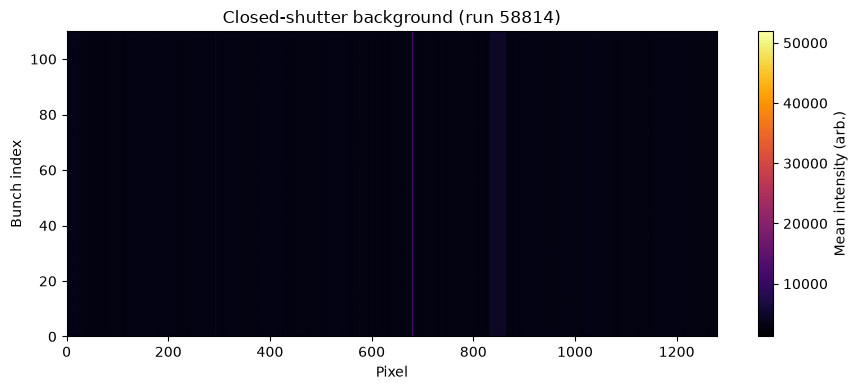

In [5]:
vls_bg = (
    load_raw_h5(BG_RUN_NO, config=2, max_files=MAX_FILES,
                train_length=TRAIN_LENGTH)
    .roll_vls_bunches(GOTTHARD_ROLL)
    .vls.mean(0)
)
print(f"background source: run {BG_RUN_NO}")
print(f"background shape : {vls_bg.shape}")

fig, ax = plt.subplots(figsize=(9, 4))
norm = (mcolors.LogNorm(vmin=max(np.nanmin(vls_bg), 1e-3),
                        vmax=np.nanmax(vls_bg))
        if LOG_MAP else None)
im = ax.pcolormesh(vls_bg, cmap="inferno", shading="auto", norm=norm)
fig.colorbar(im, ax=ax, label="Mean intensity (arb.)")
ax.set_xlabel("Pixel")
ax.set_ylabel("Bunch index")
ax.set_title(f"Closed-shutter background (run {BG_RUN_NO})")
fig.tight_layout()
plt.show()

In [4]:
def load_and_prepare(run_no, bg_spec):
    """Raw load -> roll -> bg-run subtract -> crop -> auto-bg -> trim -> moments."""
    data = load_raw_h5(run_no, config=2, max_files=MAX_FILES,
                       train_length=TRAIN_LENGTH)
    data = data.roll_vls_bunches(GOTTHARD_ROLL)
    data = data.subtract_background(bg_spec)
    if ROI is not None:
        data = data.crop_vls(*ROI)
    data = data.auto_subtract_background(BG_BUNCH_RANGE)
    data = data.trim_bunches(*SIGNAL_BUNCH_RANGE)
    data = data.compute_vls_moments()
    return data


runs = {r: load_and_prepare(r, vls_bg) for r in RUN_NOS}

for run_no, data in runs.items():
    n_t, n_b, n_p = data.vls.shape
    print(f"run {run_no}: vls shape={data.vls.shape}, "
          f"crop={data.vls_crop_roi}, bg={data.vls_background_roi}, "
          f"shots={n_t * n_b}")

Loading 6 raw H5 file(s) for run 58815 (config 2).
  reading FLASH2_USER1_main_run58815_file1_20260605T232239.1.h5
  reading FLASH2_USER1_main_run58815_file2_20260605T232330.1.h5
  reading FLASH2_USER1_main_run58815_file3_20260605T232410.1.h5
  reading FLASH2_USER1_main_run58815_file4_20260605T232449.1.h5
  reading FLASH2_USER1_main_run58815_file5_20260605T232529.1.h5
  reading FLASH2_USER1_main_run58815_file6_20260605T232608.1.h5
Loaded 2156 trains x 110 bunches.
Loading 9 raw H5 file(s) for run 58816 (config 2).
  reading FLASH2_USER1_main_run58816_file1_20260606T000122.1.h5
  reading FLASH2_USER1_main_run58816_file2_20260606T000213.1.h5
  reading FLASH2_USER1_main_run58816_file3_20260606T000253.1.h5
  reading FLASH2_USER1_main_run58816_file4_20260606T000332.1.h5
  reading FLASH2_USER1_main_run58816_file5_20260606T000412.1.h5
  reading FLASH2_USER1_main_run58816_file6_20260606T000452.1.h5
  reading FLASH2_USER1_main_run58816_file7_20260606T000531.1.h5
  reading FLASH2_USER1_main_run5

## Calibration cell 1: Geometrical

Calibration scan: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5 
Run: 58794 
Energy source: set_wavelength_1


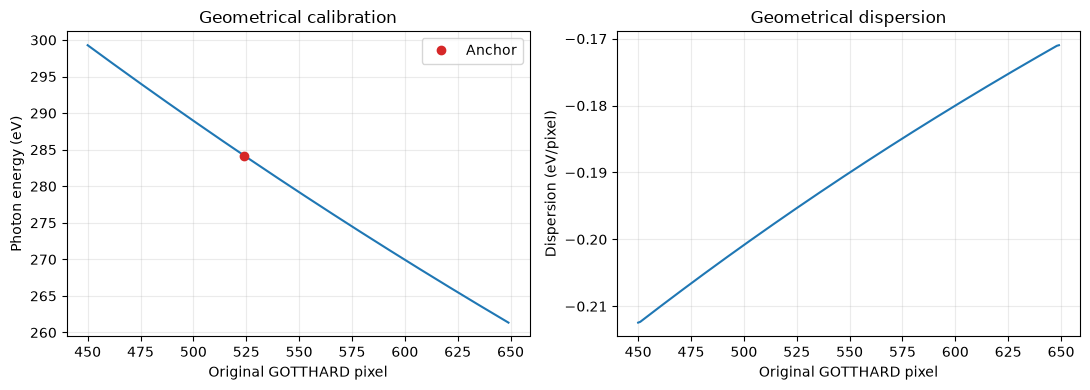

In [ ]:
# --- 1. Geometrical calibration: review these settings for the NEW instrument configuration ---
from historical.static_xas_analysis import convert_pixels_to_energy
from pathlib import Path

CAL_INPUT_H5 = Path(path_config.XAS_STATIC_DIR) / 'run58794_static_xas.h5'  # replace with NEW calibration scan
CAL_JSON = PROJECT_ROOT / 'calibrations' / f'{CAL_INPUT_H5.stem}_energy_calibration.json'
CAL_SAVE = False                 # only enable after reviewing both plots and energy references
CAL_GEOMETRY_REVIEWED = False    # set True after verifying geometry, magnification and anchor

# Historical values below are illustrative; do NOT assume they apply to the next beamtime.
CAL_GEOMETRY = dict(source_to_grating_m=0.85, grating_to_screen_m=0.5429,
    incident_angle_deg=86.78, groove_density_lines_per_mm=1200., diffraction_order=1,
    magnification=3.0, pixel_pitch_m=50e-6, axis_sign=1)
CAL_ANCHOR = dict(pixel=524., energy_eV=284.2)  # must be established for NEW beamtime
CAL_INVERSE_SAMPLES = 20000

if not CAL_INPUT_H5.is_file(): raise FileNotFoundError(CAL_INPUT_H5)
with h5py.File(CAL_INPUT_H5, 'r') as f:
    for key in ('vls','vls_pixels','n_shots','nominal_energies'):
        if key not in f: raise KeyError(f'Missing {key} in {CAL_INPUT_H5}')
    CAL_PIXELS = f['vls_pixels'][:].astype(float)
    CAL_SECTION_ENERGIES = f['nominal_energies'][:].astype(float)
    if f['vls'].ndim != 3 or f['vls'].shape[0] != CAL_SECTION_ENERGIES.size or f['vls'].shape[2] != CAL_PIXELS.size:
        raise ValueError('Expected vls (section, shot, pixel) and matching energies/pixels')
    CAL_RUN_ID = str(f.attrs.get('run_no', 'unknown'))
    CAL_ENERGY_SOURCE = str(f.attrs.get('section_energy_source', 'not recorded'))
if not np.all(np.diff(CAL_PIXELS) > 0): raise ValueError('Pixel coordinates must increase')
if np.unique(CAL_SECTION_ENERGIES[np.isfinite(CAL_SECTION_ENERGIES)]).size < 4:
    raise ValueError('A single-energy run cannot calibrate dispersion: acquire >=4 distinct energy settings')

CAL_GEOMETRY_RANGE = (float(np.nanmin(CAL_SECTION_ENERGIES)-25), float(np.nanmax(CAL_SECTION_ENERGIES)+25))
CAL_GEOMETRY_E, _, _ = convert_pixels_to_energy(CAL_PIXELS, CAL_GEOMETRY, CAL_ANCHOR,
    CAL_GEOMETRY_RANGE, CAL_INVERSE_SAMPLES)
CAL_GEOMETRY_E = np.asarray(CAL_GEOMETRY_E, dtype=float)
if not np.all(np.isfinite(CAL_GEOMETRY_E)) or np.any(np.diff(CAL_GEOMETRY_E) >= 0):
    raise ValueError('Non-finite/non-decreasing geometry mapping; check axis sign and inversion energy range')
if not CAL_GEOMETRY_REVIEWED:
    print('WARNING: geometrical values/anchor are HISTORICAL, NOT validated for the next beamtime')
print('Calibration scan:', CAL_INPUT_H5, '\nRun:', CAL_RUN_ID, '\nEnergy source:', CAL_ENERGY_SOURCE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(CAL_PIXELS, CAL_GEOMETRY_E, color='tab:blue')
axes[0].plot(CAL_ANCHOR['pixel'], CAL_ANCHOR['energy_eV'], 'o', color='tab:red', label='Anchor')
axes[0].set(xlabel='Original GOTTHARD pixel', ylabel='Photon energy (eV)', title='Geometrical calibration')
axes[0].legend()
axes[1].plot(CAL_PIXELS, np.gradient(CAL_GEOMETRY_E, CAL_PIXELS), color='tab:blue')
axes[1].set(xlabel='Original GOTTHARD pixel', ylabel='Dispersion (eV/pixel)', title='Geometrical dispersion')
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()



## Calibration cell 2: Empirical all-shot

Section  0: energy 284.000 eV | 4,365/79,200 reliable centres
Section  1: energy 283.500 eV | 3,948/35,160 reliable centres
Section  2: energy 283.000 eV | 18,930/39,000 reliable centres
Section  3: energy 282.500 eV | 24,239/35,040 reliable centres
Section  4: energy 282.000 eV | 29,211/35,790 reliable centres
Section  5: energy 281.500 eV | 35,502/39,720 reliable centres
Section  6: energy 281.000 eV | 32,732/35,580 reliable centres
Section  7: energy 280.500 eV | 31,303/33,240 reliable centres
Section  8: energy 280.000 eV | 36,286/38,130 reliable centres
Section  9: energy 279.500 eV | 43,827/45,570 reliable centres
Section 10: energy 279.000 eV | 37,549/38,700 reliable centres
Section 11: energy 278.500 eV | 33,431/34,290 reliable centres
Section 12: energy 278.000 eV | 34,543/35,010 reliable centres
Section 13: energy 277.500 eV | 35,376/35,700 reliable centres
Section 14: energy 277.000 eV | 16,892/17,040 reliable centres
Section 15: energy 277.000 eV | 17,212/17,400 reliable ce

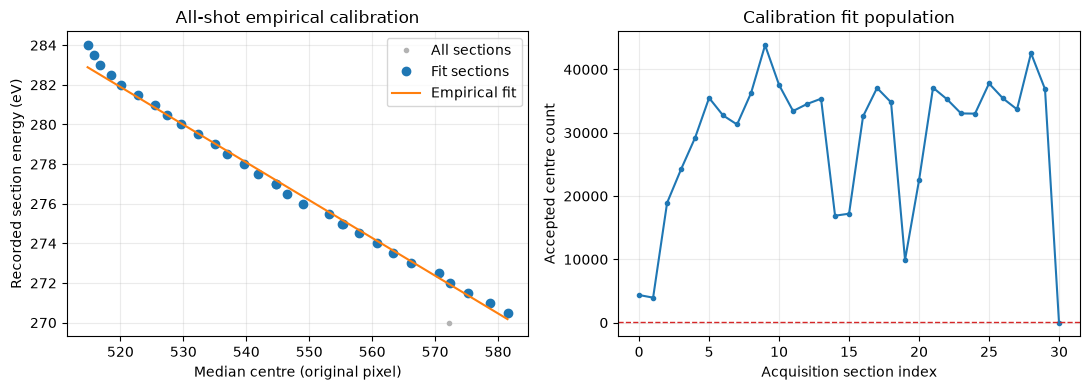

In [ ]:
# --- 2. Empirical calibration: stream ALL shots, but fit only reliable centres ---
from historical import review_calibration as empirical

CAL_CHUNK_SHOTS = 10000
CAL_GMD_DATASET = 'ml/gmd_hall_channels'  # mapped hall channel 0
CAL_USE_ML_QC = True
CAL_PEAK_SNR = 5.0
CAL_MIN_CENTRES_PER_SECTION = 100  # exclude unreliable near-empty sections from the fit
CAL_POLY_ORDER = 1
CAL_MIN_FIT_SECTIONS = 4

cal_cfg = empirical.ProcessGoodConfig(input_h5=CAL_INPUT_H5, use_ml_qc_ok=CAL_USE_ML_QC,
    energy_calibration_poly_order=CAL_POLY_ORDER, energy_calibration_min_sections=CAL_MIN_FIT_SECTIONS,
    peak_snr_threshold=CAL_PEAK_SNR)
cal_info = empirical.read_static_info(CAL_INPUT_H5)
if not np.array_equal(cal_info.vls_pixels, CAL_PIXELS) or cal_info.n_energy != len(CAL_SECTION_ENERGIES):
    raise ValueError('Calibration reader does not match processed-file pixel/section axes')
if not np.allclose(cal_info.section_energy_eV, CAL_SECTION_ENERGIES, rtol=0, atol=0.002, equal_nan=True):
    print('NOTICE: preferred raw section energies differ from nominal_energies; using reader values')
if cal_info.sigma_raw.shape != (len(CAL_PIXELS),) or not np.all(np.isfinite(cal_info.sigma_raw)):
    raise ValueError('Missing/invalid stored per-pixel background noise estimate')

cal_centres_by_section = [[] for _ in range(cal_info.n_energy)]
with h5py.File(CAL_INPUT_H5, 'r') as f:
    for key in (CAL_GMD_DATASET, 'ml/qc_ok' if CAL_USE_ML_QC else CAL_GMD_DATASET):
        if key not in f: raise KeyError(f'Missing required dataset: {key}')
    if f[CAL_GMD_DATASET].shape[:2] != f['vls'].shape[:2] or f[CAL_GMD_DATASET].ndim != 3:
        raise ValueError('Mapped GMD and VLS shot axes differ')
    if CAL_USE_ML_QC and f['ml/qc_ok'].shape != f['vls'].shape[:2]:
        raise ValueError('QC and VLS shot axes differ')
    for sec, n in enumerate(cal_info.n_shots.astype(int)):
        if n < 0 or n > f['vls'].shape[1]: raise ValueError(f'Invalid n_shots for section {sec}')
        for start in range(0, n, CAL_CHUNK_SHOTS):
            stop = min(start + CAL_CHUNK_SHOTS, n)
            spectra = f['vls'][sec, start:stop, :].astype(float)
            gmd = f[CAL_GMD_DATASET][sec, start:stop, 0].astype(float)
            qc = f['ml/qc_ok'][sec, start:stop] if CAL_USE_ML_QC else np.ones(stop-start, dtype=bool)
            basic = empirical.basic_qc_mask(spectra, gmd, qc, cal_cfg)
            peaks = empirical.peak_metrics(spectra, cal_info.sigma_raw, cal_info.vls_pixels, cal_cfg)
            keep = basic & np.isfinite(peaks['center_pixel']) & (peaks['peak_snr'] > CAL_PEAK_SNR)
            if np.any(keep): cal_centres_by_section[sec].append(peaks['center_pixel'][keep])
        print(f'Section {sec:2d}: energy {cal_info.section_energy_eV[sec]:.3f} eV | '
              f'{sum(map(len,cal_centres_by_section[sec])):,}/{n:,} reliable centres')

cal_centres, cal_counts, _, _ = empirical._summarize_section_centers(cal_centres_by_section, cal_info.n_energy)
cal_fit_centres, cal_fit_counts = cal_centres.copy(), cal_counts.copy()
cal_fit_centres[cal_counts < CAL_MIN_CENTRES_PER_SECTION] = np.nan
cal_fit_counts[cal_counts < CAL_MIN_CENTRES_PER_SECTION] = 0
cal_fit_mask = np.isfinite(cal_fit_centres) & np.isfinite(cal_info.section_energy_eV) & (cal_fit_counts > 0)
if cal_fit_mask.sum() < CAL_MIN_FIT_SECTIONS or np.unique(cal_info.section_energy_eV[cal_fit_mask]).size < CAL_POLY_ORDER+1:
    raise ValueError('Insufficient populated, distinct energy sections for empirical calibration')
CAL_EMP_COEFF, _, _ = empirical.fit_vls_pixel_energy_calibration(cal_info, cal_fit_centres, cal_fit_counts, cal_cfg)
print('Empirical coefficients (descending powers):', CAL_EMP_COEFF)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cal_centres, cal_info.section_energy_eV, '.', color='0.7', label='All sections')
axes[0].plot(cal_fit_centres[cal_fit_mask], cal_info.section_energy_eV[cal_fit_mask], 'o', label='Fit sections')
px = np.linspace(np.nanmin(cal_fit_centres), np.nanmax(cal_fit_centres), 300)
axes[0].plot(px, np.polyval(CAL_EMP_COEFF, px), '-', label='Empirical fit')
axes[0].set(xlabel='Median centre (original pixel)', ylabel='Recorded section energy (eV)', title='All-shot empirical calibration')
axes[0].legend()
axes[1].plot(np.arange(cal_info.n_energy), cal_counts, 'o-', markersize=3)
axes[1].axhline(CAL_MIN_CENTRES_PER_SECTION, color='tab:red', ls='--', lw=1)
axes[1].set(xlabel='Acquisition section index', ylabel='Accepted centre count', title='Calibration fit population')
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()



## Calibration cell 3: Comparison and JSON save

Fit sections: 30 | distinct energies: 28
Empirical RMS residual (eV): 0.3235403374404916
Geometry RMS residual (eV): 3.012206479145682
Empirical - geometry at fitted sections (min/max eV): -3.127454115451144 -3.0088239521344917


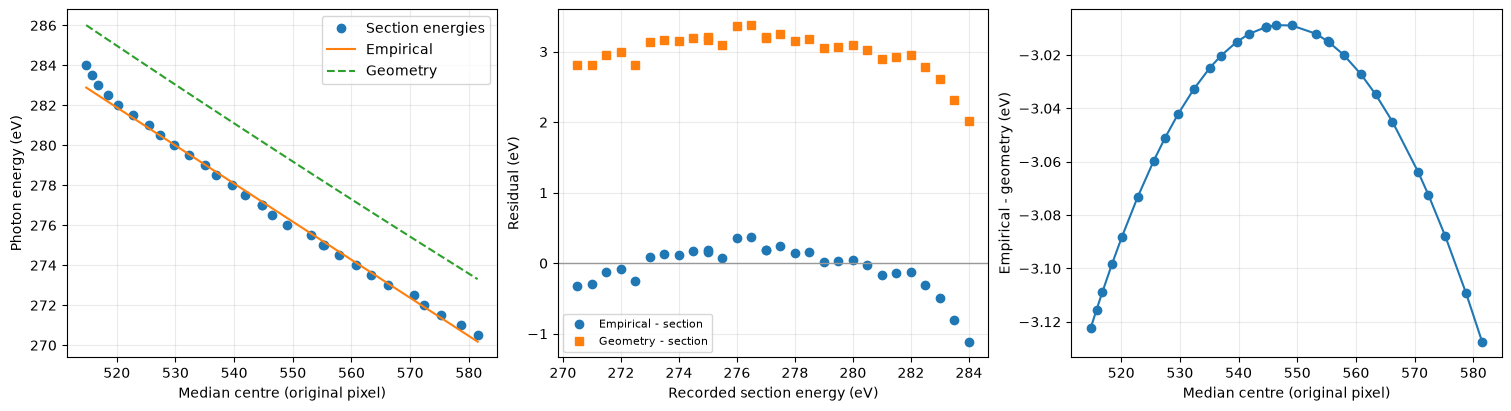

NOT SAVED. Inspect plots, validate reference energies, then set CAL_SAVE=True in cell 1 and rerun this cell.


In [ ]:
# --- 3. Compare at identical centre pixels and optionally SAVE JSON (no overwrite) ---
import json
from datetime import datetime, timezone

cal_x = cal_fit_centres[cal_fit_mask]
cal_reference_e = cal_info.section_energy_eV[cal_fit_mask]
cal_emp_e = np.polyval(CAL_EMP_COEFF, cal_x)
if not np.all(np.diff(CAL_PIXELS) > 0):
    raise ValueError('Geometry interpolation requires increasing pixel positions')
if not np.all(np.isfinite(CAL_GEOMETRY_E)):
    raise ValueError('Non-finite geometrical energy calibration')
if np.any((cal_x < CAL_PIXELS[0]) | (cal_x > CAL_PIXELS[-1])):
    raise ValueError('Calibration centres lie outside the geometrical pixel axis')
cal_geo_e = np.interp(cal_x, CAL_PIXELS, CAL_GEOMETRY_E)
cal_emp_resid = cal_emp_e - cal_reference_e
cal_geo_resid = cal_geo_e - cal_reference_e
print('Fit sections:', len(cal_x), '| distinct energies:', np.unique(cal_reference_e).size)
print('Empirical RMS residual (eV):', np.sqrt(np.mean(cal_emp_resid**2)))
print('Geometry RMS residual (eV):', np.sqrt(np.mean(cal_geo_resid**2)))
print('Empirical - geometry at fitted sections (min/max eV):',
      np.min(cal_emp_e-cal_geo_e), np.max(cal_emp_e-cal_geo_e))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
order = np.argsort(cal_x)
axes[0].plot(cal_x, cal_reference_e, 'o', label='Section energies')
axes[0].plot(cal_x[order], cal_emp_e[order], '-', label='Empirical')
axes[0].plot(cal_x[order], cal_geo_e[order], '--', label='Geometry')
axes[0].set(xlabel='Median centre (original pixel)', ylabel='Photon energy (eV)')
axes[0].legend()
axes[1].plot(cal_reference_e, cal_emp_resid, 'o', label='Empirical - section')
axes[1].plot(cal_reference_e, cal_geo_resid, 's', label='Geometry - section')
axes[1].axhline(0, color='0.6', lw=1)
axes[1].set(xlabel='Recorded section energy (eV)', ylabel='Residual (eV)')
axes[1].legend(fontsize=8)
axes[2].plot(cal_x[order], (cal_emp_e-cal_geo_e)[order], 'o-')
axes[2].set(xlabel='Median centre (original pixel)', ylabel='Empirical - geometry (eV)')
for ax in axes: ax.grid(alpha=0.25)
plt.show()

if CAL_SAVE:
    if not CAL_GEOMETRY_REVIEWED:
        raise RuntimeError('Set CAL_GEOMETRY_REVIEWED=True only after reviewing NEW geometry and anchor')
    def json_array(arr):
        return [float(v) if np.isfinite(v) else None for v in np.asarray(arr).ravel()]
    payload = dict(schema='gotthard_pixel_energy_v1', created_utc=datetime.now(timezone.utc).isoformat(),
        source_h5=str(CAL_INPUT_H5.resolve()), source_run=CAL_RUN_ID,
        energy_label_source=CAL_ENERGY_SOURCE,
        absolute_energy_validated=False,  # change only after independent energy-reference validation
        pixel_axis=json_array(CAL_PIXELS),
        geometry=dict(parameters=CAL_GEOMETRY, anchor=CAL_ANCHOR, energy_eV=json_array(CAL_GEOMETRY_E)),
        empirical=dict(coefficients_descending=json_array(CAL_EMP_COEFF), polynomial_order=CAL_POLY_ORDER,
            snr_threshold=CAL_PEAK_SNR, min_accepted_centres_per_section=CAL_MIN_CENTRES_PER_SECTION,
            use_ml_qc=CAL_USE_ML_QC, gmd_dataset=CAL_GMD_DATASET,
            section_energy_eV=json_array(cal_info.section_energy_eV),
            section_median_pixel=json_array(cal_centres), accepted_centres_per_section=cal_counts.astype(int).tolist(),
            fitted_section_indices=np.flatnonzero(cal_fit_mask).tolist()))
    CAL_JSON.parent.mkdir(parents=True, exist_ok=True)
    with CAL_JSON.open('x') as file: json.dump(payload, file, indent=2, allow_nan=False)
    print('Saved calibration:', CAL_JSON)
else:
    print('NOT SAVED. Inspect plots, validate reference energies, then set CAL_SAVE=True in cell 1 and rerun this cell.')

# In notebooks 03/04, after loading the JSON:
# with open(CAL_JSON) as f: calibration = json.load(f)
# E_emp = np.polyval(calibration['empirical']['coefficients_descending'], pixels)
# E_geo = np.interp(pixels, calibration['pixel_axis'], calibration['geometry']['energy_eV'])

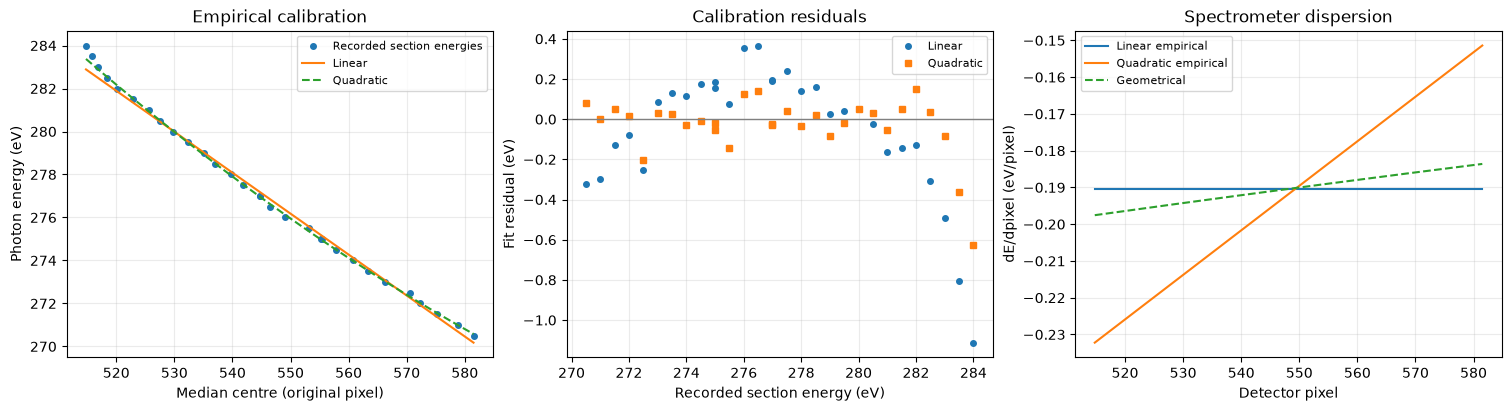

Linear coefficients: [-1.90536581e-01  3.80974070e+02]
Quadratic coefficients: [ 6.05732825e-04 -8.55871512e-01  5.63444976e+02]
Linear residual RMS:     0.3235 eV
Quadratic residual RMS:  0.1510 eV
Improvement in RMS:      53.3%

Dispersion at pixel 544.7:
  Linear empirical:     -0.19054 eV/pixel
  Quadratic empirical:  -0.19600 eV/pixel
  Geometrical:          -0.19113 eV/pixel

Quadratic dispersion range: -0.23222 to -0.15140 eV/pixel


In [ ]:
# --- Calibration diagnostic: linear versus quadratic fit and dispersion ---
from dataclasses import replace

# Reuse the fitted section centres; do not reprocess GOTTHARD spectra.
x = np.asarray(cal_fit_centres[cal_fit_mask], dtype=float)
y = np.asarray(cal_info.section_energy_eV[cal_fit_mask], dtype=float)

if CAL_POLY_ORDER != 1 or len(CAL_EMP_COEFF) != 2:
    raise ValueError('This comparison expects the existing empirical calibration to be linear')
if len(x) < max(CAL_MIN_FIT_SECTIONS, 3) or np.unique(x).size < 3:
    raise ValueError('Insufficient distinct spectral centres for quadratic calibration')

# Linear coefficients already calculated in cell 2.
coeff_linear = np.asarray(CAL_EMP_COEFF, dtype=float)

# Refit only the section medians with a quadratic using the same fitting routine.
quad_cfg = replace(cal_cfg, energy_calibration_poly_order=2)
coeff_quad, _, _ = empirical.fit_vls_pixel_energy_calibration(
    cal_info, cal_fit_centres, cal_fit_counts, quad_cfg
)

# Predictions and residuals at the same measured section centres.
linear_e = np.polyval(coeff_linear, x)
quad_e = np.polyval(coeff_quad, x)
linear_resid = linear_e - y
quad_resid = quad_e - y

# Energy dispersion is the derivative dE/d(pixel).
px = np.linspace(x.min(), x.max(), 300)
disp_linear = np.polyval(np.polyder(coeff_linear), px)
disp_quad = np.polyval(np.polyder(coeff_quad), px)

geometry_dispersion = np.gradient(CAL_GEOMETRY_E, CAL_PIXELS)
disp_geometry = np.interp(px, CAL_PIXELS, geometry_dispersion)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# Panel 1: calibration curves.
order = np.argsort(x)
axes[0].plot(x, y, 'o', ms=4, label='Recorded section energies')
axes[0].plot(x[order], linear_e[order], '-', label='Linear')
axes[0].plot(x[order], quad_e[order], '--', label='Quadratic')
axes[0].set(xlabel='Median centre (original pixel)', ylabel='Photon energy (eV)',
            title='Empirical calibration')
axes[0].legend(fontsize=8)

# Panel 2: residuals using identical section data.
axes[1].plot(y, linear_resid, 'o', ms=4, label='Linear')
axes[1].plot(y, quad_resid, 's', ms=4, label='Quadratic')
axes[1].axhline(0, color='0.5', lw=1)
axes[1].set(xlabel='Recorded section energy (eV)', ylabel='Fit residual (eV)',
            title='Calibration residuals')
axes[1].legend(fontsize=8)

# Panel 3: compare local dispersion.
axes[2].plot(px, disp_linear, label='Linear empirical')
axes[2].plot(px, disp_quad, label='Quadratic empirical')
axes[2].plot(px, disp_geometry, '--', label='Geometrical')
axes[2].set(xlabel='Detector pixel', ylabel='dE/dpixel (eV/pixel)',
            title='Spectrometer dispersion')
axes[2].legend(fontsize=8)

for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

# Numerical comparison.
rms_linear = np.sqrt(np.mean(linear_resid**2))
rms_quad = np.sqrt(np.mean(quad_resid**2))
px_reference = float(np.median(x))

print('Linear coefficients:', coeff_linear)
print('Quadratic coefficients:', coeff_quad)
print(f'Linear residual RMS:     {rms_linear:.4f} eV')
print(f'Quadratic residual RMS:  {rms_quad:.4f} eV')
print(f'Improvement in RMS:      {100*(1-rms_quad/rms_linear):.1f}%')
print(f'\nDispersion at pixel {px_reference:.1f}:')
print(f'  Linear empirical:     {np.polyval(np.polyder(coeff_linear), px_reference):.5f} eV/pixel')
print(f'  Quadratic empirical:  {np.polyval(np.polyder(coeff_quad), px_reference):.5f} eV/pixel')
print(f'  Geometrical:          {np.interp(px_reference, CAL_PIXELS, geometry_dispersion):.5f} eV/pixel')
print(f'\nQuadratic dispersion range: {disp_quad.min():.5f} to {disp_quad.max():.5f} eV/pixel')

## Magnification from grid shadows

Source: `analysis/notebooks/gotthard_magnification.ipynb`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; cells 3, 5, 7, 9.

Independent runs 58892/58893, grid spacing 0.68 mm and detector pitch 0.050 mm. Retain smoothing, prominence rule, peak distances and plots. No roll or pulse selection is added. Measured magnification is not automatically used by another calibration.

Adaptations: Imports use local helpers and verified paths; calculation cells unchanged.

In [18]:
import glob
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


In [19]:
CONFIG = 2
SIGNAL_RUN_NO = 58892
BACKGROUND_RUN_NO = 58893
RAW_DIR = Path(path_config.RAW_H5_DIR)
MAX_FILES = None

GRID_SPACING_MM = 0.68
PIXEL_SIZE_MM = 0.050  # 50 um

SMOOTH_SIGMA_PIXELS = 3.0
MIN_PEAK_DISTANCE_PIXELS = 10
MIN_PEAK_PROMINENCE = None
PROFILE_ROI = None  # set to (start, stop) to restrict fringe detection

VLS_PATH = '/FL2/Support Infrastructure/Gotthard/images/value'

def infer_vls_shape(run_no, raw_dir=RAW_DIR):
    pattern = str(raw_dir / f'*run{run_no}*.h5')
    paths = sorted(glob.glob(pattern))
    if not paths:
        raise FileNotFoundError(f'No raw H5 files matching {pattern!r}.')
    with h5py.File(paths[0], 'r') as f:
        shape = f[VLS_PATH].shape
    return shape, paths[0]

signal_shape, signal_first_file = infer_vls_shape(SIGNAL_RUN_NO)
background_shape, background_first_file = infer_vls_shape(BACKGROUND_RUN_NO)

TRAIN_LENGTH = int(signal_shape[1])
N_VLS_PIXELS = int(signal_shape[2])

print(f'raw dir              : {RAW_DIR}')
print(f'signal run           : {SIGNAL_RUN_NO}')
print(f'background run       : {BACKGROUND_RUN_NO}')
print(f'signal first file    : {Path(signal_first_file).name}')
print(f'background first file: {Path(background_first_file).name}')
print(f'signal raw shape     : {signal_shape}')
print(f'background raw shape : {background_shape}')
print(f'train length         : {TRAIN_LENGTH}')
print(f'n vls pixels         : {N_VLS_PIXELS}')
print(f'grid spacing         : {GRID_SPACING_MM} mm')
print(f'pixel size           : {PIXEL_SIZE_MM} mm')

raw dir              : /asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1
signal run           : 58892
background run       : 58893
signal first file    : FLASH2_USER1_main_run58892_file1_20260608T105203.1.h5
background first file: FLASH2_USER1_main_run58893_file1_20260608T105614.1.h5
signal raw shape     : (443, 110, 1280)
background raw shape : (390, 110, 1280)
train length         : 110
n vls pixels         : 1280
grid spacing         : 0.68 mm
pixel size           : 0.05 mm


In [20]:
def load_run(run_no):
    data = load_raw_h5(
        run_no=run_no,
        config=CONFIG,
        raw_dir=RAW_DIR,
        train_length=TRAIN_LENGTH,
        n_vls_pixels=N_VLS_PIXELS,
        max_files=MAX_FILES,
    )
    if not isinstance(data, ExperimentData):
        raise TypeError('Expected ExperimentData from data_loading.load_raw_h5.')
    if data.vls is None:
        raise RuntimeError(f'Run {run_no} has no VLS data.')
    return data

signal_data = load_run(SIGNAL_RUN_NO)
background_data = load_run(BACKGROUND_RUN_NO)

print(f'signal data shape    : {signal_data.vls.shape}')
print(f'background data shape: {background_data.vls.shape}')
print(f'signal trains        : {signal_data.n_trains}')
print(f'background trains    : {background_data.n_trains}')
print(f'signal bunches       : {signal_data.n_bunches}')
print(f'background bunches   : {background_data.n_bunches}')

Loading 1 raw H5 file(s) for run 58892 (config 2).
  reading FLASH2_USER1_main_run58892_file1_20260608T105203.1.h5
Loaded 443 trains x 110 bunches.
Loading 1 raw H5 file(s) for run 58893 (config 2).
  reading FLASH2_USER1_main_run58893_file1_20260608T105614.1.h5
Loaded 390 trains x 110 bunches.
signal data shape    : (443, 110, 1280)
background data shape: (390, 110, 1280)
signal trains        : 443
background trains    : 390
signal bunches       : 110
background bunches   : 110


common mean image shape: (110, 1280)
diff min / max         : -59.5 / 806


/tmp/ipykernel_590911/3855287225.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


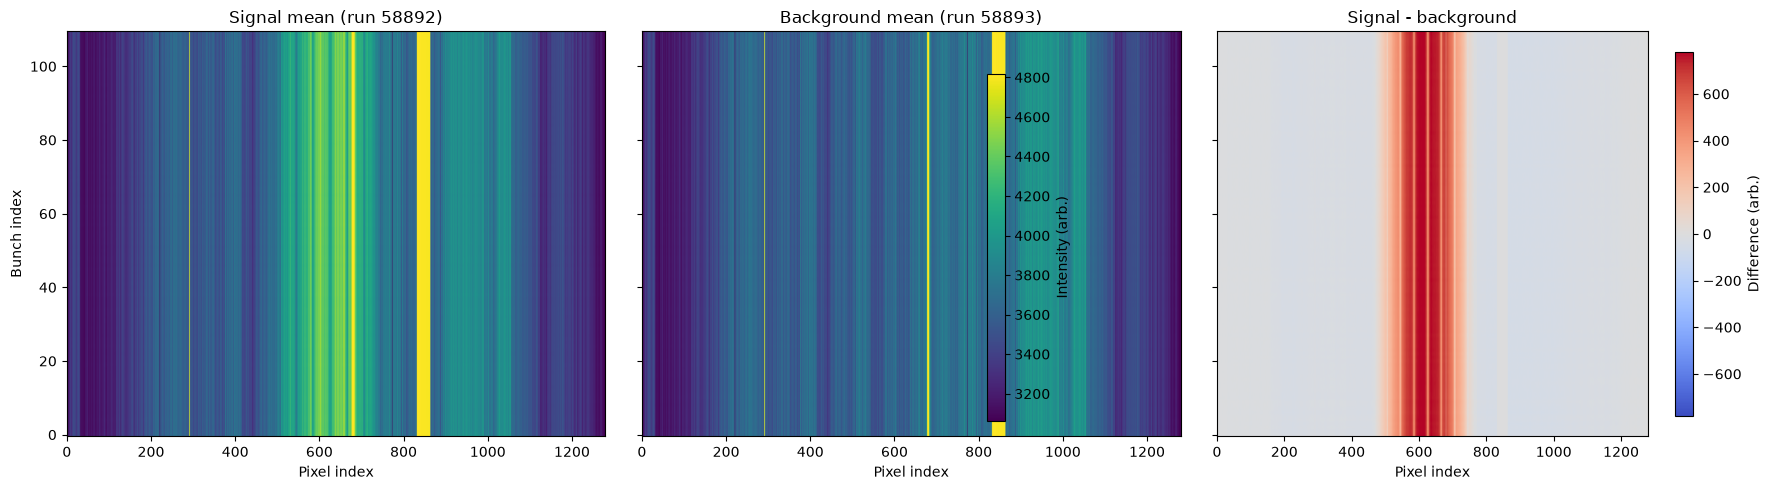

In [21]:
signal_mean = np.nanmean(signal_data.vls, axis=0)
background_mean = np.nanmean(background_data.vls, axis=0)

n_bunches = min(signal_mean.shape[0], background_mean.shape[0])
n_pixels = min(signal_mean.shape[1], background_mean.shape[1])

signal_mean = signal_mean[:n_bunches, :n_pixels]
background_mean = background_mean[:n_bunches, :n_pixels]
diff_image = signal_mean - background_mean

print(f'common mean image shape: {diff_image.shape}')
print(f'diff min / max         : {np.nanmin(diff_image):.3g} / {np.nanmax(diff_image):.3g}')

vmin = np.nanpercentile(np.concatenate([signal_mean.ravel(), background_mean.ravel()]), 1)
vmax = np.nanpercentile(np.concatenate([signal_mean.ravel(), background_mean.ravel()]), 99)
dlim = np.nanpercentile(np.abs(diff_image), 99)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

im0 = axes[0].imshow(signal_mean, aspect='auto', origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
axes[0].set_title(f'Signal mean (run {SIGNAL_RUN_NO})')

im1 = axes[1].imshow(background_mean, aspect='auto', origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
axes[1].set_title(f'Background mean (run {BACKGROUND_RUN_NO})')

im2 = axes[2].imshow(diff_image, aspect='auto', origin='lower', cmap='coolwarm', vmin=-dlim, vmax=dlim)
axes[2].set_title('Signal - background')

for ax in axes:
    ax.set_xlabel('Pixel index')
axes[0].set_ylabel('Bunch index')

fig.colorbar(im0, ax=axes[:2], shrink=0.9, label='Intensity (arb.)')
fig.colorbar(im2, ax=axes[2], shrink=0.9, label='Difference (arb.)')
fig.tight_layout()
plt.show()

detected shadows         : 3
number of spacings       : 2
median spacing           : 40.50 px
mean spacing             : 40.50 px
std of spacings          : 0.50 px
detector spacing         : 2.0250 mm
object spacing           : 0.6800 mm
magnification            : 2.9779 x


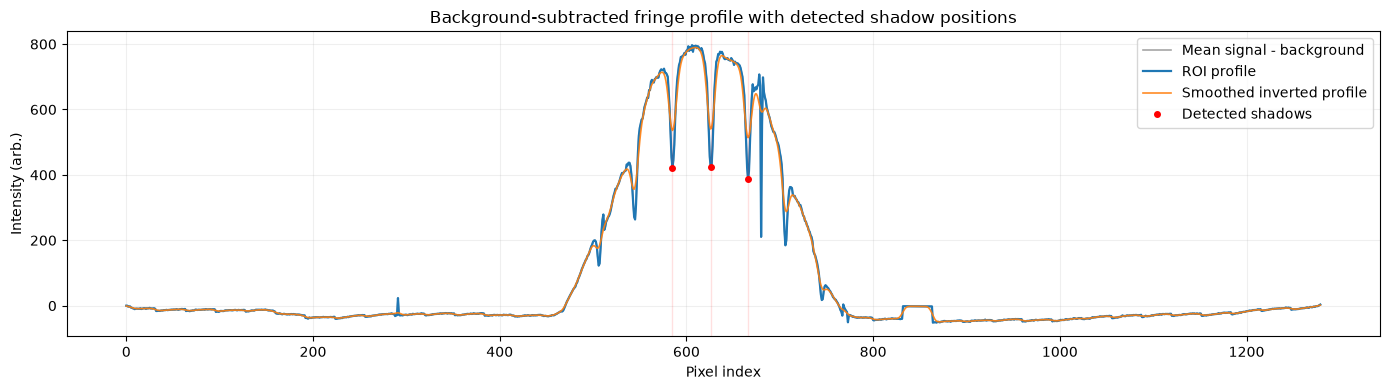

In [22]:
profile = np.nanmean(diff_image, axis=0)
x = np.arange(profile.size)

if PROFILE_ROI is None:
    roi_start, roi_stop = 0, profile.size
else:
    roi_start, roi_stop = PROFILE_ROI
    roi_start = max(0, int(roi_start))
    roi_stop = min(profile.size, int(roi_stop))

x_roi = x[roi_start:roi_stop]
profile_roi = profile[roi_start:roi_stop]
smoothed_dark = gaussian_filter1d(-profile_roi, sigma=SMOOTH_SIGMA_PIXELS, mode='nearest')

if MIN_PEAK_PROMINENCE is None:
    prominence = max(float(np.nanstd(smoothed_dark)) * 0.35, float(np.nanmax(smoothed_dark)) * 0.05)
else:
    prominence = float(MIN_PEAK_PROMINENCE)

peaks, props = find_peaks(
    smoothed_dark,
    distance=MIN_PEAK_DISTANCE_PIXELS,
    prominence=prominence,
)
peak_pixels = x_roi[peaks]
spacings_px = np.diff(peak_pixels)

if peak_pixels.size < 2:
    raise RuntimeError('Could not detect at least two fringes. Adjust PROFILE_ROI or the peak-finding parameters.')

median_spacing_px = float(np.nanmedian(spacings_px))
mean_spacing_px = float(np.nanmean(spacings_px))
std_spacing_px = float(np.nanstd(spacings_px))
spacing_mm = median_spacing_px * PIXEL_SIZE_MM
magnification = spacing_mm / GRID_SPACING_MM

print(f'detected shadows         : {peak_pixels.size}')
print(f'number of spacings       : {spacings_px.size}')
print(f'median spacing           : {median_spacing_px:.2f} px')
print(f'mean spacing             : {mean_spacing_px:.2f} px')
print(f'std of spacings          : {std_spacing_px:.2f} px')
print(f'detector spacing         : {spacing_mm:.4f} mm')
print(f'object spacing           : {GRID_SPACING_MM:.4f} mm')
print(f'magnification            : {magnification:.4f} x')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(x, profile, color='0.65', lw=1.2, label='Mean signal - background')
ax.plot(x_roi, profile_roi, color='tab:blue', lw=1.6, label='ROI profile')
ax.plot(x_roi, -smoothed_dark, color='tab:orange', lw=1.2, alpha=0.9, label='Smoothed inverted profile')
ax.plot(peak_pixels, profile_roi[peaks], 'ro', ms=4, label='Detected shadows')
for px in peak_pixels:
    ax.axvline(px, color='red', alpha=0.12, lw=1)
ax.set_xlabel('Pixel index')
ax.set_ylabel('Intensity (arb.)')
ax.set_title('Background-subtracted fringe profile with detected shadow positions')
ax.grid(alpha=0.2)
ax.legend(loc='best')
fig.tight_layout()
plt.show()

In [23]:
del signal_data, background_data


## Independent historical pixel-energy mapping

Source: `analysis/scripts/gotthard_energy_pixel_map.py`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; USER_CONFIG, USER_CALIBRATION, USER_QUERY, main, energy_to_pixel, pixel_to_energy.

Standalone source uses magnification 3 and anchor 590 px at 270 eV; query pixels [530,560,590], range 260–290 eV. Its dataclass default magnification 8 is overridden explicitly by USER_CONFIG. Keep this distinct from the 58794 anchor (524 px at 284.2 eV). No anchor is newly validated or transferred to runs 58815/58816.

Adaptations: Verbatim local module; explicitly call its existing query/printing entry point. No new fit or calibration plot is invented.

In [26]:
from historical import gotthard_energy_pixel_map as pixel_map
pixel_map.main()
print('Separate 58794 parameters:', PIXEL_MAP_CONFIG, PIXEL_MAP_CALIBRATION)
print('Measured shadow magnification is diagnostic; fixed calibrations remain unchanged.')


=== Spectrometer Configuration ===
source_to_grating_m          : 0.85
grating_to_screen_m          : 0.5429
incident_angle_deg           : 86.78
groove_density_lines_per_mm  : 1200.0
diffraction_order            : 1
magnification                : 3
pixel_pitch_m                : 5e-05
axis_sign                    : 1
=== Calibration ===
pixel at calibration energy  : 590.0
calibration energy (eV)      : 270.0

Pixel -> Energy
  pixel = 530.000000 -> E =   281.161559 eV
  pixel = 560.000000 -> E =   275.489852 eV
  pixel = 590.000000 -> E =   270.000000 eV

P list: 530.000000, 560.000000, 590.000000
E list: 281.161559, 275.489852, 270.000000
Separate 58794 parameters: {'source_to_grating_m': 0.85, 'grating_to_screen_m': 0.5429, 'incident_angle_deg': 86.78, 'groove_density_lines_per_mm': 1200.0, 'diffraction_order': 1, 'magnification': 3.0, 'pixel_pitch_m': 5e-05, 'axis_sign': 1} {'pixel': 524.0, 'energy_eV': 284.2}
Measured shadow magnification is diagnostic; fixed calibrations remain 